<a href="https://colab.research.google.com/github/manasa5F0/It1220/blob/master/Example_stress_strain_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import os

# ==============================================================================
# OPTIONAL HELPER: Create sample CSV if it doesn't already exist on Colab
# ==============================================================================
file_path = 'stress_strain_practice.csv'

if not os.path.exists(file_path):
    print("Creating sample 'stress_strain_practice.csv' for testing...\n")
    sample_data = {
        'Test_ID': [101, 102, 103, 104, 105, 106, 107, 108],
        'Material': ['Structural Steel', 'Structural Steel', 'Aluminum 6061', 'Aluminum 6061',
                     'Titanium Ti-6Al-4V', 'Titanium Ti-6Al-4V', 'Polymer (ABS)', 'Polymer (ABS)'],
        'Force_N': [25000, 26200, 14000, 14500, 48000, 50000, 3200, 3100],
        'Cross_Section_Area_mm2': [50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0],
        'Elongation_mm': [1.2, 1.25, 1.8, 1.9, 0.9, 0.95, 2.5, 2.4],
        'Original_Length_mm': [100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0],
        'Test_Date': ['2026-01-10', '2026-01-10', '2026-01-11', '2026-01-11',
                     '2026-01-12', '2026-01-12', '2026-01-13', '2026-01-13']
    }
    pd.DataFrame(sample_data).to_csv(file_path, index=False)

# ==============================================================================
# STEP 1: Load CSV file and display the first 5 rows
# ==============================================================================
print("--- STEP 1: Loading CSV and displaying first 5 rows ---")
df = pd.read_csv(file_path)

# Display the head of the dataframe
print(df.head(5))
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 2: Calculate Stress (MPa) = Force (N) / Area (mm²)
# Note: 1 N/mm² is equivalent to 1 MPa (Megapascal)
# ==============================================================================
print("--- STEP 2: Calculating Stress (MPa) ---")
df['Stress_MPa'] = df['Force_N'] / df['Cross_Section_Area_mm2']
print(df[['Test_ID', 'Material', 'Force_N', 'Cross_Section_Area_mm2', 'Stress_MPa']].head())
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 3: Calculate Strain (%) = (Elongation / Original_Length) * 100
# ==============================================================================
print("--- STEP 3: Calculating Strain (%) ---")
df['Strain_pct'] = (df['Elongation_mm'] / df['Original_Length_mm']) * 100
print(df[['Test_ID', 'Material', 'Elongation_mm', 'Original_Length_mm', 'Strain_pct']].head())
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 4: Group results by Material and show average Stress and Strain
# ==============================================================================
print("--- STEP 4: Average Stress and Strain by Material ---")
avg_by_material = df.groupby('Material')[['Stress_MPa', 'Strain_pct']].mean().reset_index()
avg_by_material.columns = ['Material', 'Avg_Stress_MPa', 'Avg_Strain_pct']
print(avg_by_material.to_string(index=False))
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 5: Identify which material type is strongest (highest average stress)
# ==============================================================================
print("--- STEP 5: Identifying Strongest Material ---")
strongest_row = avg_by_material.loc[avg_by_material['Avg_Stress_MPa'].idxmax()]
strongest_material = strongest_row['Material']
highest_avg_stress = strongest_row['Avg_Stress_MPa']

print(f"🏆 Strongest Material: {strongest_material}")
print(f"⚡ Highest Average Stress: {highest_avg_stress:.2f} MPa")
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 6: Create a summary showing Min, Max, and Average Stress for each material
# ==============================================================================
print("--- STEP 6: Material Stress Summary (Min, Max, Avg) ---")
stress_summary = df.groupby('Material')['Stress_MPa'].agg(
    Min_Stress_MPa='min',
    Max_Stress_MPa='max',
    Avg_Stress_MPa='mean'
).reset_index()

# Round values for cleaner presentation
stress_summary['Min_Stress_MPa'] = stress_summary['Min_Stress_MPa'].round(2)
stress_summary['Max_Stress_MPa'] = stress_summary['Max_Stress_MPa'].round(2)
stress_summary['Avg_Stress_MPa'] = stress_summary['Avg_Stress_MPa'].round(2)

print(stress_summary.to_string(index=False))
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 7: Export full updated results and summary table to new CSV files
# ==============================================================================
print("--- STEP 7: Exporting Results to CSV ---")

output_results_file = 'stress_strain_results.csv'
output_summary_file = 'stress_strain_material_summary.csv'

# Save main dataset with new calculated columns
df.to_csv(output_results_file, index=False)
print(f"✅ Full test results saved to: {output_results_file}")

# Save material summary dataset
stress_summary.to_csv(output_summary_file, index=False)
print(f"✅ Material summary saved to: {output_summary_file}")

print("\nProcessing complete!")

Creating sample 'stress_strain_practice.csv' for testing...

--- STEP 1: Loading CSV and displaying first 5 rows ---
   Test_ID            Material  Force_N  Cross_Section_Area_mm2  \
0      101    Structural Steel    25000                    50.0   
1      102    Structural Steel    26200                    50.0   
2      103       Aluminum 6061    14000                    50.0   
3      104       Aluminum 6061    14500                    50.0   
4      105  Titanium Ti-6Al-4V    48000                    50.0   

   Elongation_mm  Original_Length_mm   Test_Date  
0           1.20               100.0  2026-01-10  
1           1.25               100.0  2026-01-10  
2           1.80               100.0  2026-01-11  
3           1.90               100.0  2026-01-11  
4           0.90               100.0  2026-01-12  


--- STEP 2: Calculating Stress (MPa) ---
   Test_ID            Material  Force_N  Cross_Section_Area_mm2  Stress_MPa
0      101    Structural Steel    25000                

--- STEP 1: Loading CSV and displaying first 5 rows ---
   Test_ID            Material  Force_N  Cross_Section_Area_mm2  \
0      101    Structural Steel    25000                    50.0   
1      102    Structural Steel    26200                    50.0   
2      103       Aluminum 6061    14000                    50.0   
3      104       Aluminum 6061    14500                    50.0   
4      105  Titanium Ti-6Al-4V    48000                    50.0   

   Elongation_mm  Original_Length_mm   Test_Date  
0           1.20               100.0  2026-01-10  
1           1.25               100.0  2026-01-10  
2           1.80               100.0  2026-01-11  
3           1.90               100.0  2026-01-11  
4           0.90               100.0  2026-01-12  


--- STEP 2: Calculating Stress (MPa) ---
   Test_ID            Material  Force_N  Cross_Section_Area_mm2  Stress_MPa
0      101    Structural Steel    25000                    50.0       500.0
1      102    Structural Steel    26200 

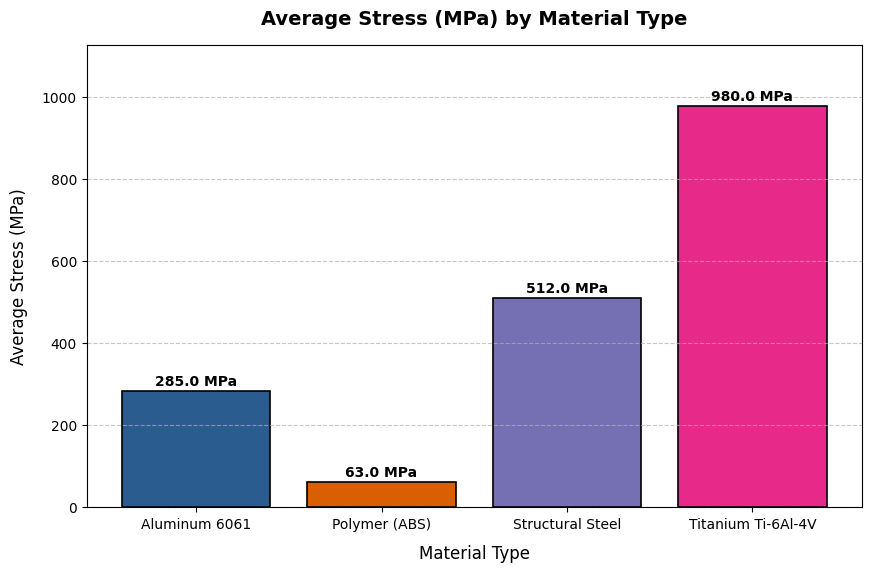

✅ Bar chart saved to: stress_vs_material_barchart.png

Processing complete!


In [2]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

# ==============================================================================
# OPTIONAL HELPER: Create sample CSV if it doesn't already exist on Colab
# ==============================================================================
file_path = 'stress_strain_practice.csv'

if not os.path.exists(file_path):
    print("Creating sample 'stress_strain_practice.csv' for testing...\n")
    sample_data = {
        'Test_ID': [101, 102, 103, 104, 105, 106, 107, 108],
        'Material': ['Structural Steel', 'Structural Steel', 'Aluminum 6061', 'Aluminum 6061',
                     'Titanium Ti-6Al-4V', 'Titanium Ti-6Al-4V', 'Polymer (ABS)', 'Polymer (ABS)'],
        'Force_N': [25000, 26200, 14000, 14500, 48000, 50000, 3200, 3100],
        'Cross_Section_Area_mm2': [50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0],
        'Elongation_mm': [1.2, 1.25, 1.8, 1.9, 0.9, 0.95, 2.5, 2.4],
        'Original_Length_mm': [100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0],
        'Test_Date': ['2026-01-10', '2026-01-10', '2026-01-11', '2026-01-11',
                     '2026-01-12', '2026-01-12', '2026-01-13', '2026-01-13']
    }
    pd.DataFrame(sample_data).to_csv(file_path, index=False)

# ==============================================================================
# STEP 1: Load CSV file and display the first 5 rows
# ==============================================================================
print("--- STEP 1: Loading CSV and displaying first 5 rows ---")
df = pd.read_csv(file_path)

# Display the head of the dataframe
print(df.head(5))
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 2: Calculate Stress (MPa) = Force (N) / Area (mm²)
# Note: 1 N/mm² is equivalent to 1 MPa (Megapascal)
# ==============================================================================
print("--- STEP 2: Calculating Stress (MPa) ---")
df['Stress_MPa'] = df['Force_N'] / df['Cross_Section_Area_mm2']
print(df[['Test_ID', 'Material', 'Force_N', 'Cross_Section_Area_mm2', 'Stress_MPa']].head())
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 3: Calculate Strain (%) = (Elongation / Original_Length) * 100
# ==============================================================================
print("--- STEP 3: Calculating Strain (%) ---")
df['Strain_pct'] = (df['Elongation_mm'] / df['Original_Length_mm']) * 100
print(df[['Test_ID', 'Material', 'Elongation_mm', 'Original_Length_mm', 'Strain_pct']].head())
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 4: Group results by Material and show average Stress and Strain
# ==============================================================================
print("--- STEP 4: Average Stress and Strain by Material ---")
avg_by_material = df.groupby('Material')[['Stress_MPa', 'Strain_pct']].mean().reset_index()
avg_by_material.columns = ['Material', 'Avg_Stress_MPa', 'Avg_Strain_pct']
print(avg_by_material.to_string(index=False))
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 5: Identify which material type is strongest (highest average stress)
# ==============================================================================
print("--- STEP 5: Identifying Strongest Material ---")
strongest_row = avg_by_material.loc[avg_by_material['Avg_Stress_MPa'].idxmax()]
strongest_material = strongest_row['Material']
highest_avg_stress = strongest_row['Avg_Stress_MPa']

print(f"🏆 Strongest Material: {strongest_material}")
print(f"⚡ Highest Average Stress: {highest_avg_stress:.2f} MPa")
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 6: Create a summary showing Min, Max, and Average Stress for each material
# ==============================================================================
print("--- STEP 6: Material Stress Summary (Min, Max, Avg) ---")
stress_summary = df.groupby('Material')['Stress_MPa'].agg(
    Min_Stress_MPa='min',
    Max_Stress_MPa='max',
    Avg_Stress_MPa='mean'
).reset_index()

# Round values for cleaner presentation
stress_summary['Min_Stress_MPa'] = stress_summary['Min_Stress_MPa'].round(2)
stress_summary['Max_Stress_MPa'] = stress_summary['Max_Stress_MPa'].round(2)
stress_summary['Avg_Stress_MPa'] = stress_summary['Avg_Stress_MPa'].round(2)

print(stress_summary.to_string(index=False))
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 7: Export full updated results and summary table to new CSV files
# ==============================================================================
print("--- STEP 7: Exporting Results to CSV ---")

output_results_file = 'stress_strain_results.csv'
output_summary_file = 'stress_strain_material_summary.csv'

# Save main dataset with new calculated columns
df.to_csv(output_results_file, index=False)
print(f"✅ Full test results saved to: {output_results_file}")

# Save material summary dataset
stress_summary.to_csv(output_summary_file, index=False)
print(f"✅ Material summary saved to: {output_summary_file}")

# ==============================================================================
# STEP 8: Visualize Average Stress vs. Material Type (Bar Chart)
# ==============================================================================
print("\n--- STEP 8: Generating Bar Chart Visualization ---")

# Set up figure dimensions
plt.figure(figsize=(10, 6))

# Plot bar chart for Average Stress per Material
bars = plt.bar(
    avg_by_material['Material'],
    avg_by_material['Avg_Stress_MPa'],
    color=['#2b5c8f', '#d95f02', '#7570b3', '#e7298a'],
    edgecolor='black',
    linewidth=1.2
)

# Set chart title and axis labels
plt.title('Average Stress (MPa) by Material Type', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Material Type', fontsize=12, labelpad=10)
plt.ylabel('Average Stress (MPa)', fontsize=12, labelpad=10)

# Add horizontal grid lines for improved readability
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Annotate value labels on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 5,
        f'{height:.1f} MPa',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

# Adjust y-axis limit to accommodate text annotations
plt.ylim(0, max(avg_by_material['Avg_Stress_MPa']) * 1.15)

# Save chart image file for Colab environment
chart_file = 'stress_vs_material_barchart.png'
plt.savefig(chart_file, dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ Bar chart saved to: {chart_file}")

print("\nProcessing complete!")

--- STEP 1: Loading CSV and displaying first 5 rows ---
   Test_ID            Material  Force_N  Cross_Section_Area_mm2  \
0      101    Structural Steel    25000                    50.0   
1      102    Structural Steel    26200                    50.0   
2      103       Aluminum 6061    14000                    50.0   
3      104       Aluminum 6061    14500                    50.0   
4      105  Titanium Ti-6Al-4V    48000                    50.0   

   Elongation_mm  Original_Length_mm   Test_Date  
0           1.20               100.0  2026-01-10  
1           1.25               100.0  2026-01-10  
2           1.80               100.0  2026-01-11  
3           1.90               100.0  2026-01-11  
4           0.90               100.0  2026-01-12  


--- STEP 2: Calculating Stress (MPa) ---
   Test_ID            Material  Force_N  Cross_Section_Area_mm2  Stress_MPa  \
0      101    Structural Steel    25000                    50.0       500.0   
1      102    Structural Steel    

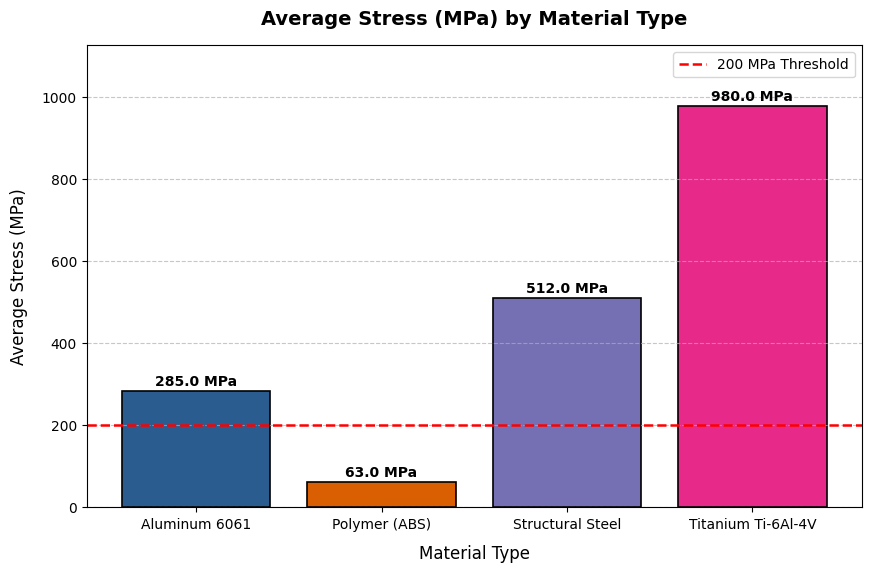

✅ Bar chart saved to: stress_vs_material_barchart.png

Processing complete!


In [3]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

# ==============================================================================
# OPTIONAL HELPER: Create sample CSV if it doesn't already exist on Colab
# ==============================================================================
file_path = 'stress_strain_practice.csv'

if not os.path.exists(file_path):
    print("Creating sample 'stress_strain_practice.csv' for testing...\n")
    sample_data = {
        'Test_ID': [101, 102, 103, 104, 105, 106, 107, 108],
        'Material': ['Structural Steel', 'Structural Steel', 'Aluminum 6061', 'Aluminum 6061',
                     'Titanium Ti-6Al-4V', 'Titanium Ti-6Al-4V', 'Polymer (ABS)', 'Polymer (ABS)'],
        'Force_N': [25000, 26200, 14000, 14500, 48000, 50000, 3200, 3100],
        'Cross_Section_Area_mm2': [50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0],
        'Elongation_mm': [1.2, 1.25, 1.8, 1.9, 0.9, 0.95, 2.5, 2.4],
        'Original_Length_mm': [100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0],
        'Test_Date': ['2026-01-10', '2026-01-10', '2026-01-11', '2026-01-11',
                     '2026-01-12', '2026-01-12', '2026-01-13', '2026-01-13']
    }
    pd.DataFrame(sample_data).to_csv(file_path, index=False)

# ==============================================================================
# STEP 1: Load CSV file and display the first 5 rows
# ==============================================================================
print("--- STEP 1: Loading CSV and displaying first 5 rows ---")
df = pd.read_csv(file_path)

# Display the head of the dataframe
print(df.head(5))
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 2: Calculate Stress (MPa) = Force (N) / Area (mm²)
# Note: 1 N/mm² is equivalent to 1 MPa (Megapascal)
# ==============================================================================
print("--- STEP 2: Calculating Stress (MPa) ---")
df['Stress_MPa'] = df['Force_N'] / df['Cross_Section_Area_mm2']
# Flag tests where stress exceeds 200 MPa threshold
df['Exceeds_200MPa'] = df['Stress_MPa'] > 200
print(df[['Test_ID', 'Material', 'Force_N', 'Cross_Section_Area_mm2', 'Stress_MPa', 'Exceeds_200MPa']].head())
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 3: Calculate Strain (%) = (Elongation / Original_Length) * 100
# ==============================================================================
print("--- STEP 3: Calculating Strain (%) ---")
df['Strain_pct'] = (df['Elongation_mm'] / df['Original_Length_mm']) * 100
print(df[['Test_ID', 'Material', 'Elongation_mm', 'Original_Length_mm', 'Strain_pct']].head())
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 4: Group results by Material and show average Stress and Strain
# ==============================================================================
print("--- STEP 4: Average Stress and Strain by Material ---")
avg_by_material = df.groupby('Material')[['Stress_MPa', 'Strain_pct']].mean().reset_index()
avg_by_material.columns = ['Material', 'Avg_Stress_MPa', 'Avg_Strain_pct']
print(avg_by_material.to_string(index=False))
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 5: Identify which material type is strongest (highest average stress)
# ==============================================================================
print("--- STEP 5: Identifying Strongest Material ---")
strongest_row = avg_by_material.loc[avg_by_material['Avg_Stress_MPa'].idxmax()]
strongest_material = strongest_row['Material']
highest_avg_stress = strongest_row['Avg_Stress_MPa']

print(f"🏆 Strongest Material: {strongest_material}")
print(f"⚡ Highest Average Stress: {highest_avg_stress:.2f} MPa")

# Highlight individual test runs exceeding 200 MPa threshold
high_stress_tests = df[df['Stress_MPa'] > 200]
print(f"\n⚠️  FOUND {len(high_stress_tests)} TEST(S) EXCEEDING 200 MPa STRESS THRESHOLD:")
print(high_stress_tests[['Test_ID', 'Material', 'Force_N', 'Stress_MPa', 'Test_Date']].to_string(index=False))
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 6: Create a summary showing Min, Max, and Average Stress for each material
# ==============================================================================
print("--- STEP 6: Material Stress Summary (Min, Max, Avg) ---")
stress_summary = df.groupby('Material')['Stress_MPa'].agg(
    Min_Stress_MPa='min',
    Max_Stress_MPa='max',
    Avg_Stress_MPa='mean'
).reset_index()

# Round values for cleaner presentation
stress_summary['Min_Stress_MPa'] = stress_summary['Min_Stress_MPa'].round(2)
stress_summary['Max_Stress_MPa'] = stress_summary['Max_Stress_MPa'].round(2)
stress_summary['Avg_Stress_MPa'] = stress_summary['Avg_Stress_MPa'].round(2)

print(stress_summary.to_string(index=False))
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 7: Export full updated results and summary table to new CSV files
# ==============================================================================
print("--- STEP 7: Exporting Results to CSV ---")

output_results_file = 'stress_strain_results.csv'
output_summary_file = 'stress_strain_material_summary.csv'

# Save main dataset with new calculated columns
df.to_csv(output_results_file, index=False)
print(f"✅ Full test results saved to: {output_results_file}")

# Save material summary dataset
stress_summary.to_csv(output_summary_file, index=False)
print(f"✅ Material summary saved to: {output_summary_file}")

# ==============================================================================
# STEP 8: Visualize Average Stress vs. Material Type (Bar Chart)
# ==============================================================================
print("\n--- STEP 8: Generating Bar Chart Visualization ---")

# Set up figure dimensions
plt.figure(figsize=(10, 6))

# Plot bar chart for Average Stress per Material
bars = plt.bar(
    avg_by_material['Material'],
    avg_by_material['Avg_Stress_MPa'],
    color=['#2b5c8f', '#d95f02', '#7570b3', '#e7298a'],
    edgecolor='black',
    linewidth=1.2
)

# Set chart title and axis labels
plt.title('Average Stress (MPa) by Material Type', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Material Type', fontsize=12, labelpad=10)
plt.ylabel('Average Stress (MPa)', fontsize=12, labelpad=10)

# Add horizontal grid lines for improved readability
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Highlight 200 MPa threshold on plot
plt.axhline(y=200, color='red', linestyle='--', linewidth=1.8, label='200 MPa Threshold')
plt.legend(loc='upper right', fontsize=10)

# Annotate value labels on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 5,
        f'{height:.1f} MPa',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

# Adjust y-axis limit to accommodate text annotations
plt.ylim(0, max(avg_by_material['Avg_Stress_MPa']) * 1.15)

# Save chart image file for Colab environment
chart_file = 'stress_vs_material_barchart.png'
plt.savefig(chart_file, dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ Bar chart saved to: {chart_file}")

print("\nProcessing complete!")

--- STEP 1: Loading CSV and checking for missing values ---
Checking dataset integrity...
✅ No missing values detected in dataset.

Preview of cleaned dataset:
   Test_ID            Material  Force_N  Cross_Section_Area_mm2  \
0      101    Structural Steel    25000                    50.0   
1      102    Structural Steel    26200                    50.0   
2      103       Aluminum 6061    14000                    50.0   
3      104       Aluminum 6061    14500                    50.0   
4      105  Titanium Ti-6Al-4V    48000                    50.0   

   Elongation_mm  Original_Length_mm   Test_Date  
0           1.20               100.0  2026-01-10  
1           1.25               100.0  2026-01-10  
2           1.80               100.0  2026-01-11  
3           1.90               100.0  2026-01-11  
4           0.90               100.0  2026-01-12  


--- STEP 2: Calculating Stress (MPa) ---
   Test_ID            Material  Force_N  Cross_Section_Area_mm2  Stress_MPa  \
0      10

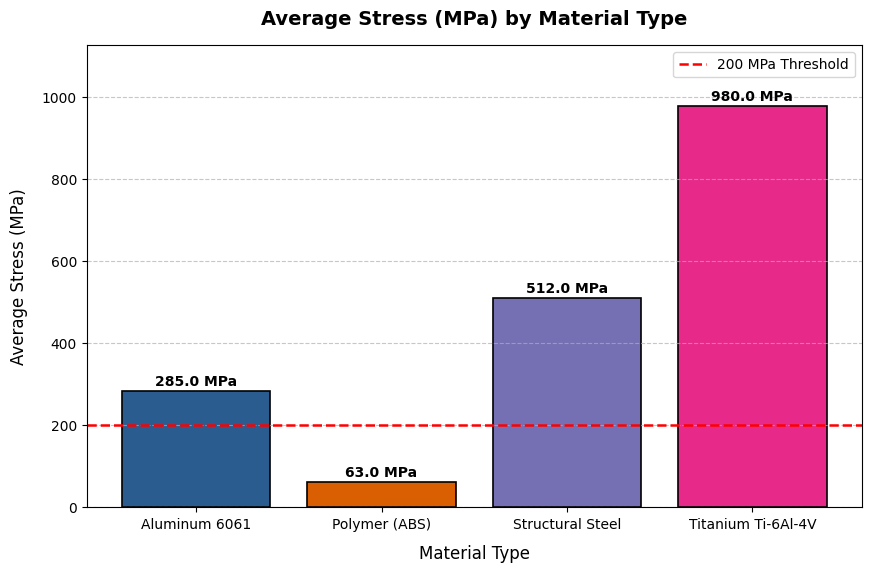

✅ Bar chart saved to: stress_vs_material_barchart.png

Processing complete!


In [4]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

# ==============================================================================
# OPTIONAL HELPER: Create sample CSV if it doesn't already exist on Colab
# ==============================================================================
file_path = 'stress_strain_practice.csv'

if not os.path.exists(file_path):
    print("Creating sample 'stress_strain_practice.csv' for testing...\n")
    sample_data = {
        'Test_ID': [101, 102, 103, 104, 105, 106, 107, 108],
        'Material': ['Structural Steel', 'Structural Steel', 'Aluminum 6061', 'Aluminum 6061',
                     'Titanium Ti-6Al-4V', 'Titanium Ti-6Al-4V', 'Polymer (ABS)', 'Polymer (ABS)'],
        'Force_N': [25000, 26200, 14000, 14500, 48000, 50000, 3200, 3100],
        'Cross_Section_Area_mm2': [50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0],
        'Elongation_mm': [1.2, 1.25, 1.8, 1.9, 0.9, 0.95, 2.5, 2.4],
        'Original_Length_mm': [100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0],
        'Test_Date': ['2026-01-10', '2026-01-10', '2026-01-11', '2026-01-11',
                     '2026-01-12', '2026-01-12', '2026-01-13', '2026-01-13']
    }
    pd.DataFrame(sample_data).to_csv(file_path, index=False)

# ==============================================================================
# STEP 1: Load CSV file and display the first 5 rows
# ==============================================================================
print("--- STEP 1: Loading CSV and checking for missing values ---")
df = pd.read_csv(file_path)

# --- Error Handling: Check for missing values (NaNs) ---
print("Checking dataset integrity...")
missing_summary = df.isnull().sum()

if df.isnull().values.any():
    print("\n⚠️ WARNING: Missing values detected in the following column(s):")
    print(missing_summary[missing_summary > 0].to_string())

    # Drop rows missing crucial numeric calculation fields
    required_cols = ['Force_N', 'Cross_Section_Area_mm2', 'Elongation_mm', 'Original_Length_mm']
    initial_count = len(df)
    df = df.dropna(subset=required_cols).copy()
    dropped_count = initial_count - len(df)
    print(f"\n--> Cleaned dataset: Dropped {dropped_count} row(s) with missing calculation values.\n")
else:
    print("✅ No missing values detected in dataset.\n")

# --- Error Handling: Prevent Division by Zero or Invalid Dimensions ---
invalid_mask = (df['Cross_Section_Area_mm2'] <= 0) | (df['Original_Length_mm'] <= 0)
if invalid_mask.any():
    print("⚠️ WARNING: Found rows with zero or negative Area/Length values:")
    print(df[invalid_mask][['Test_ID', 'Material', 'Cross_Section_Area_mm2', 'Original_Length_mm']])
    print("--> Dropping invalid records to prevent calculation errors...\n")
    df = df[~invalid_mask].copy()

# Display the head of the cleaned dataframe
print("Preview of cleaned dataset:")
print(df.head(5))
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 2: Calculate Stress (MPa) = Force (N) / Area (mm²)
# Note: 1 N/mm² is equivalent to 1 MPa (Megapascal)
# ==============================================================================
print("--- STEP 2: Calculating Stress (MPa) ---")
df['Stress_MPa'] = df['Force_N'] / df['Cross_Section_Area_mm2']
# Flag tests where stress exceeds 200 MPa threshold
df['Exceeds_200MPa'] = df['Stress_MPa'] > 200
print(df[['Test_ID', 'Material', 'Force_N', 'Cross_Section_Area_mm2', 'Stress_MPa', 'Exceeds_200MPa']].head())
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 3: Calculate Strain (%) = (Elongation / Original_Length) * 100
# ==============================================================================
print("--- STEP 3: Calculating Strain (%) ---")
df['Strain_pct'] = (df['Elongation_mm'] / df['Original_Length_mm']) * 100
print(df[['Test_ID', 'Material', 'Elongation_mm', 'Original_Length_mm', 'Strain_pct']].head())
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 4: Group results by Material and show average Stress and Strain
# ==============================================================================
print("--- STEP 4: Average Stress and Strain by Material ---")
avg_by_material = df.groupby('Material')[['Stress_MPa', 'Strain_pct']].mean().reset_index()
avg_by_material.columns = ['Material', 'Avg_Stress_MPa', 'Avg_Strain_pct']
print(avg_by_material.to_string(index=False))
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 5: Identify which material type is strongest (highest average stress)
# ==============================================================================
print("--- STEP 5: Identifying Strongest Material ---")
strongest_row = avg_by_material.loc[avg_by_material['Avg_Stress_MPa'].idxmax()]
strongest_material = strongest_row['Material']
highest_avg_stress = strongest_row['Avg_Stress_MPa']

print(f"🏆 Strongest Material: {strongest_material}")
print(f"⚡ Highest Average Stress: {highest_avg_stress:.2f} MPa")

# Highlight individual test runs exceeding 200 MPa threshold
high_stress_tests = df[df['Stress_MPa'] > 200]
print(f"\n⚠️  FOUND {len(high_stress_tests)} TEST(S) EXCEEDING 200 MPa STRESS THRESHOLD:")
print(high_stress_tests[['Test_ID', 'Material', 'Force_N', 'Stress_MPa', 'Test_Date']].to_string(index=False))
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 6: Create a summary showing Min, Max, and Average Stress for each material
# ==============================================================================
print("--- STEP 6: Material Stress Summary (Min, Max, Avg) ---")
stress_summary = df.groupby('Material')['Stress_MPa'].agg(
    Min_Stress_MPa='min',
    Max_Stress_MPa='max',
    Avg_Stress_MPa='mean'
).reset_index()

# Round values for cleaner presentation
stress_summary['Min_Stress_MPa'] = stress_summary['Min_Stress_MPa'].round(2)
stress_summary['Max_Stress_MPa'] = stress_summary['Max_Stress_MPa'].round(2)
stress_summary['Avg_Stress_MPa'] = stress_summary['Avg_Stress_MPa'].round(2)

print(stress_summary.to_string(index=False))
print("\n" + "="*70 + "\n")

# ==============================================================================
# STEP 7: Export full updated results and summary table to new CSV files
# ==============================================================================
print("--- STEP 7: Exporting Results to CSV ---")

output_results_file = 'stress_strain_results.csv'
output_summary_file = 'stress_strain_material_summary.csv'

# Save main dataset with new calculated columns
df.to_csv(output_results_file, index=False)
print(f"✅ Full test results saved to: {output_results_file}")

# Save material summary dataset
stress_summary.to_csv(output_summary_file, index=False)
print(f"✅ Material summary saved to: {output_summary_file}")

# ==============================================================================
# STEP 8: Visualize Average Stress vs. Material Type (Bar Chart)
# ==============================================================================
print("\n--- STEP 8: Generating Bar Chart Visualization ---")

# Set up figure dimensions
plt.figure(figsize=(10, 6))

# Plot bar chart for Average Stress per Material
bars = plt.bar(
    avg_by_material['Material'],
    avg_by_material['Avg_Stress_MPa'],
    color=['#2b5c8f', '#d95f02', '#7570b3', '#e7298a'],
    edgecolor='black',
    linewidth=1.2
)

# Set chart title and axis labels
plt.title('Average Stress (MPa) by Material Type', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Material Type', fontsize=12, labelpad=10)
plt.ylabel('Average Stress (MPa)', fontsize=12, labelpad=10)

# Add horizontal grid lines for improved readability
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Highlight 200 MPa threshold on plot
plt.axhline(y=200, color='red', linestyle='--', linewidth=1.8, label='200 MPa Threshold')
plt.legend(loc='upper right', fontsize=10)

# Annotate value labels on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 5,
        f'{height:.1f} MPa',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

# Adjust y-axis limit to accommodate text annotations
plt.ylim(0, max(avg_by_material['Avg_Stress_MPa']) * 1.15)

# Save chart image file for Colab environment
chart_file = 'stress_vs_material_barchart.png'
plt.savefig(chart_file, dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ Bar chart saved to: {chart_file}")

print("\nProcessing complete!")

In [6]:
# @title AI prompt cell

import ipywidgets as widgets
from IPython.display import display, HTML, Markdown,clear_output
from google.colab import ai

dropdown = widgets.Dropdown(
    options=[],
    layout={'width': 'auto'}
)

def update_model_list(new_options):
    dropdown.options = new_options
update_model_list(ai.list_models())

text_input = widgets.Textarea(
    placeholder='Ask me anything....',
    layout={'width': 'auto', 'height': '100px'},
)

button = widgets.Button(
    description='Submit Text',
    disabled=False,
    tooltip='Click to submit the text',
    icon='check'
)

output_area = widgets.Output(
     layout={'width': 'auto', 'max_height': '300px','overflow_y': 'scroll'}
)

def on_button_clicked(b):
    with output_area:
        output_area.clear_output(wait=False)
        accumulated_content = ""
        for new_chunk in ai.generate_text(prompt=text_input.value, model_name=dropdown.value, stream=True):
            if new_chunk is None:
                continue
            accumulated_content += new_chunk
            clear_output(wait=True)
            display(Markdown(accumulated_content))

button.on_click(on_button_clicked)
vbox = widgets.GridBox([dropdown, text_input, button, output_area])

display(HTML("""
<style>
.widget-dropdown select {
    font-size: 18px;
    font-family: "Arial", sans-serif;
}
.widget-textarea textarea {
    font-size: 18px;
    font-family: "Arial", sans-serif;
}
</style>
"""))
display(vbox)


GridBox(children=(Dropdown(layout=Layout(width='auto'), options=('google/gemini-3.1-pro-preview', 'google/gemi…